# Análisis estadístico del importe por compra

## Introducción

Este proyecto analiza el importe de las facturas de una tienda online británica utilizando el conjunto de datos Online Retail.

El archivo contiene 541.909 registros de productos facturados entre el 1 de diciembre de 2010 y el 9 de diciembre de 2011. Cada fila corresponde a una línea de factura, por lo que una compra puede ocupar varias filas.

Agruparemos estas líneas para estudiar la distribución de los importes por factura y evaluar cómo influyen los pedidos grandes en las medidas estadísticas.

## Objetivo

Describir el importe de una compra habitual mediante medidas de tendencia central, dispersión y visualizaciones, y analizar la sensibilidad del promedio a los valores extremos.

## Preguntas del análisis

- ¿Cuál es el importe medio y mediano por factura?
- ¿Qué tan diferentes son los importes entre compras?
- ¿Cuánto influyen los pedidos grandes en el promedio?
- ¿Cómo cambia la distribución al comparar grupos de compras?

## Alcance

Estudiaremos facturas de venta con cantidades y precios positivos. Excluiremos registros de cancelación y conceptos como envíos, comisiones, descuentos y ajustes contables.

El importe calculado corresponde a los productos facturados antes de posibles cancelaciones posteriores. No representa necesariamente el gasto final del cliente.

Conservaremos inicialmente las filas exactamente repetidas, porque no contamos con un identificador de línea que permita confirmar que son errores. También mantendremos las facturas sin identificación de cliente para describir los importes por compra.

## Datos y herramientas

Utilizaremos Python, pandas, NumPy y Matplotlib. El archivo `Online Retail.xlsx` debe estar en la misma carpeta que este notebook.

Fuente: Chen, D. (2015). Online Retail. UCI Machine Learning Repository.

https://doi.org/10.24432/C5BW33

## 1. Carga y selección de los registros

Cargamos el archivo Excel y preparamos los códigos de factura y producto como texto, eliminando espacios externos y unificando las letras en mayúsculas.

Seleccionamos registros con cantidades y precios positivos y excluimos las facturas cuyo código comienza con C, que identifica cancelaciones.

Separamos los conceptos identificados de envíos, comisiones, descuentos, ajustes de deuda, operaciones manuales, muestras y vales de regalo. Utilizamos sus códigos específicos, ya que algunos productos también tienen códigos con letras.

Finalmente, calculamos el importe de cada línea multiplicando la cantidad por el precio unitario.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Path("figures").mkdir(exist_ok=True)

datos_originales = pd.read_excel("Online Retail.xlsx")
datos = datos_originales.copy()

datos["InvoiceNo"] = datos["InvoiceNo"].astype("string").str.strip().str.upper()
datos["StockCode"] = datos["StockCode"].astype("string").str.strip().str.upper()

conceptos_excluidos = [
    "AMAZONFEE", "B", "BANK CHARGES", "C2", "CRUK",
    "D", "DOT", "M", "POST", "S"
]

es_cancelacion = datos["InvoiceNo"].str.startswith("C", na=False)
es_concepto_excluido = datos["StockCode"].isin(conceptos_excluidos)
es_vale = datos["StockCode"].str.startswith("GIFT_", na=False)

seleccion = (
    (datos["Quantity"] > 0)
    & (datos["UnitPrice"] > 0)
    & ~es_cancelacion
    & ~es_concepto_excluido
    & ~es_vale
)

ventas = datos.loc[seleccion].copy()
ventas["Importe"] = ventas["Quantity"] * ventas["UnitPrice"]

print("Registros originales:", len(datos))
print("Líneas de venta seleccionadas:", len(ventas))
print("Facturas distintas:", ventas["InvoiceNo"].nunique())

display(ventas.head())

Registros originales: 541909
Líneas de venta seleccionadas: 527761
Facturas distintas: 19773


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Importe
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 2. Comprobación de las facturas

Antes de agrupar las líneas, comprobamos si una factura está asociada a más de un cliente o país.

Si encontramos inconsistencias, revisaremos esos casos antes de asignar un cliente o país a cada compra.

El conteo de clientes distintos considera únicamente identificadores presentes. Por tanto, una factura con cero clientes identificados contiene solamente valores faltantes en esa columna.

In [2]:
revision_facturas = ventas.groupby("InvoiceNo").agg(
    Clientes_distintos=("CustomerID", "nunique"),
    Paises_distintos=("Country", "nunique")
)

facturas_inconsistentes = revision_facturas[
    (revision_facturas["Clientes_distintos"] > 1)
    | (revision_facturas["Paises_distintos"] > 1)
]

print("Facturas con más de un cliente o país:", len(facturas_inconsistentes))
print("Facturas sin cliente identificado:", (revision_facturas["Clientes_distintos"] == 0).sum())

display(facturas_inconsistentes.head(10))

Facturas con más de un cliente o país: 0
Facturas sin cliente identificado: 1371


,Clientes_distintos,Paises_distintos
InvoiceNo,,


### Resultado de la comprobación

La selección contiene 527.761 líneas de venta correspondientes a 19.773 facturas.

No encontramos facturas asociadas a más de un cliente o país. Esto permite agrupar las líneas por número de factura sin resolver conflictos entre esos campos.

Hay 1.371 facturas sin identificación de cliente. Las conservamos porque nuestro análisis se centra en el importe por factura, no en el gasto acumulado por persona.

## 3. Construcción de la tabla por factura

Agrupamos las líneas seleccionadas por número de factura y calculamos:

- Importe: suma de los importes de sus líneas.
- Unidades: suma de las cantidades.
- Productos distintos: número de códigos de producto diferentes.
- Líneas: cantidad de registros incluidos.

Conservamos el cliente y el país asociados a cada factura. Como fecha de referencia utilizamos la primera fecha registrada en sus líneas.

Cada fila de la nueva tabla representa una factura con al menos un producto incluido en nuestra selección. Su importe excluye los conceptos que separamos anteriormente y no descuenta cancelaciones posteriores.


In [3]:
facturas = ventas.groupby("InvoiceNo").agg(
    Fecha=("InvoiceDate", "min"),
    Cliente=("CustomerID", "first"),
    Pais=("Country", "first"),
    Importe=("Importe", "sum"),
    Unidades=("Quantity", "sum"),
    Productos_distintos=("StockCode", "nunique"),
    Lineas=("StockCode", "size")
).reset_index()

print("Número de facturas:", len(facturas))
display(facturas.head())

# Comprobamos que la agrupación conserve el importe total.
total_lineas = ventas["Importe"].sum()
total_facturas = facturas["Importe"].sum()

print("\nImporte total de las líneas:", round(total_lineas, 2))
print("Importe total de las facturas:", round(total_facturas, 2))
print("¿Coinciden los totales?", np.isclose(total_lineas, total_facturas))

Número de facturas: 19773


,InvoiceNo,Fecha,Cliente,Pais,Importe,Unidades,Productos_distintos,Lineas
0,536365,2010-12-01 08:26:00,17850.0,United Kingdom,139.12,40,7,7
1,536366,2010-12-01 08:28:00,17850.0,United Kingdom,22.20,12,2,2
2,536367,2010-12-01 08:34:00,13047.0,United Kingdom,278.73,83,12,12
3,536368,2010-12-01 08:34:00,13047.0,United Kingdom,70.05,15,4,4
4,536369,2010-12-01 08:35:00,13047.0,United Kingdom,17.85,3,1,1



Importe total de las líneas: 10271433.06
Importe total de las facturas: 10271433.06
¿Coinciden los totales? True


## 4. Estadísticas del importe por factura

Calculamos medidas de posición y dispersión para describir la distribución de los importes.

La media representa el importe promedio, mientras que la mediana divide las facturas en dos mitades: una con importes menores o iguales y otra con importes mayores o iguales.

Los percentiles permiten conocer distintos puntos de la distribución. Por ejemplo, el percentil 90 indica el importe por debajo del cual se encuentra aproximadamente el 90 % de las facturas.

El rango intercuartílico es la diferencia entre los percentiles 75 y 25 y describe la amplitud del 50 % central de los importes. La desviación estándar mide la dispersión respecto de la media y es sensible a los valores extremos.

In [4]:
importes = facturas["Importe"]

estadisticas = pd.Series({
    "Mínimo": importes.min(),
    "Percentil 25": importes.quantile(0.25),
    "Mediana": importes.median(),
    "Media": importes.mean(),
    "Percentil 75": importes.quantile(0.75),
    "Percentil 90": importes.quantile(0.90),
    "Percentil 95": importes.quantile(0.95),
    "Percentil 99": importes.quantile(0.99),
    "Máximo": importes.max(),
    "Desviación estándar": importes.std(),
    "Rango intercuartílico": importes.quantile(0.75) - importes.quantile(0.25)
})

display(estadisticas.round(2).to_frame("Importe (GBP)"))

print("Relación entre media y mediana:", round(importes.mean() / importes.median(), 2))

,Importe (GBP)
Mínimo,0.38
Percentil 25,152.40
Mediana,302.59
Media,519.47
Percentil 75,483.65
Percentil 90,918.26
Percentil 95,1509.34
Percentil 99,4408.93
Máximo,168469.60
Desviación estándar,1764.21


Relación entre media y mediana: 1.72


### Interpretación de las estadísticas

La suma de los importes por factura coincide con la suma de las líneas seleccionadas: £10.271.433,06. La agrupación conserva el total.

El importe medio por factura es de £519,47 y la mediana es de £302,59. La media supera a la mediana en un factor de 1,72, lo que sugiere una distribución con una cola hacia los importes altos.

El 50 % central de las facturas se encuentra entre £152,40 y £483,65. Aproximadamente el 90 % tiene importes de hasta £918,26 y el 99 % de hasta £4.408,93.

El máximo alcanza £168.469,60, muy por encima de esos valores. La desviación estándar, de £1.764,21, refleja una dispersión elevada y es sensible a las facturas extremas.

La mediana ofrece una referencia del centro de la distribución menos sensible a los pedidos grandes. La media sigue siendo útil para describir el importe total repartido entre todas las facturas.

## 5. Visualización de la distribución de importes

Utilizamos dos histogramas para observar la distribución:

- El primero muestra las facturas con importes de hasta el percentil 99, para distinguir mejor dónde se concentra la mayoría de las compras.
- El segundo incluye todas las facturas, con intervalos y eje horizontal en escala logarítmica, para visualizar también los importes extremos.

El límite del primer gráfico solo afecta a la visualización. No eliminamos facturas de la tabla de análisis.

En ambos gráficos señalamos la media y la mediana calculadas sobre todas las facturas.

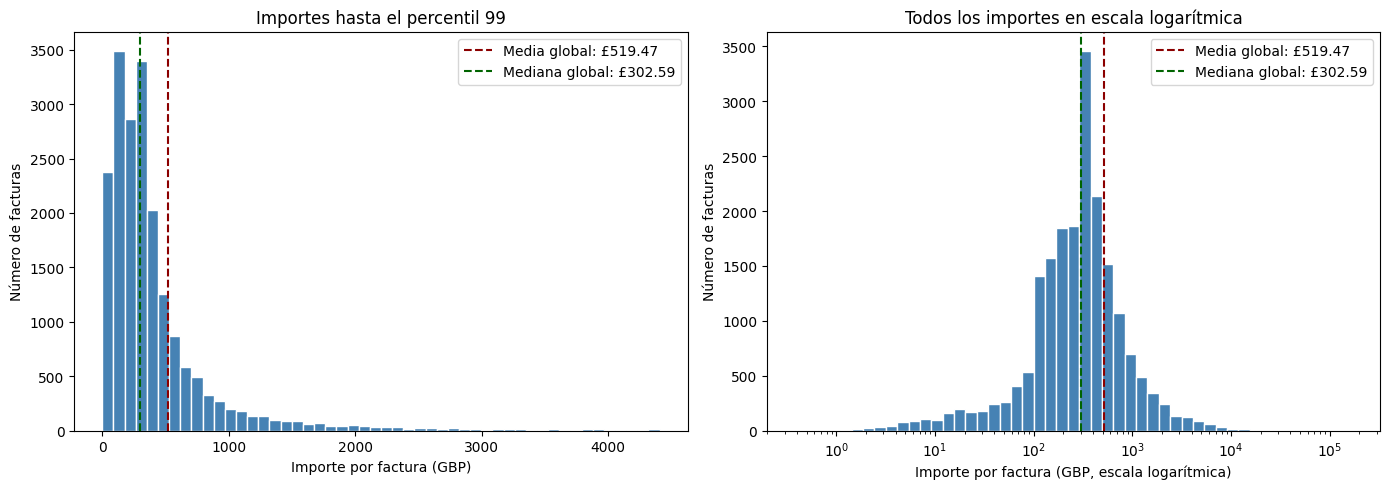

Facturas incluidas en el primer gráfico: 19575
Facturas por encima del percentil 99: 198


In [5]:
media = importes.mean()
mediana = importes.median()
limite = importes.quantile(0.99)

importes_centrales = importes[importes <= limite]
intervalos_log = np.geomspace(importes.min(), importes.max(), 50)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Ampliamos la zona donde se concentra la mayoría de las facturas.
ax[0].hist(importes_centrales, bins=50, color="steelblue", edgecolor="white")
ax[0].axvline(media, color="darkred", linestyle="--", label=f"Media global: £{media:.2f}")
ax[0].axvline(mediana, color="darkgreen", linestyle="--", label=f"Mediana global: £{mediana:.2f}")

ax[0].set_title("Importes hasta el percentil 99")
ax[0].set_xlabel("Importe por factura (GBP)")
ax[0].set_ylabel("Número de facturas")
ax[0].legend()

# Incluimos todas las facturas con intervalos logarítmicos.
ax[1].hist(importes, bins=intervalos_log, color="steelblue", edgecolor="white")
ax[1].set_xscale("log")
ax[1].axvline(media, color="darkred", linestyle="--", label=f"Media global: £{media:.2f}")
ax[1].axvline(mediana, color="darkgreen", linestyle="--", label=f"Mediana global: £{mediana:.2f}")

ax[1].set_title("Todos los importes en escala logarítmica")
ax[1].set_xlabel("Importe por factura (GBP, escala logarítmica)")
ax[1].set_ylabel("Número de facturas")
ax[1].legend()

plt.tight_layout()
fig.savefig("figures/distribucion_importes.png", dpi=160, bbox_inches="tight")
plt.show()

print("Facturas incluidas en el primer gráfico:", len(importes_centrales))
print("Facturas por encima del percentil 99:", (importes > limite).sum())

## 6. Influencia de las facturas de mayor importe

Comparamos las estadísticas de todas las facturas con dos escenarios: conservar únicamente importes hasta el percentil 99 y hasta el percentil 95.

Estos escenarios permiten evaluar cuánto cambian la media y la mediana al excluir la parte superior de la distribución. No implican que las facturas grandes sean errores ni modifican la tabla original.

También calculamos qué proporción del importe total corresponde a las facturas por encima del percentil 99.

In [6]:
p99 = importes.quantile(0.99)
p95 = importes.quantile(0.95)

hasta_p99 = importes[importes <= p99]
hasta_p95 = importes[importes <= p95]

comparacion_extremos = pd.DataFrame({
    "Todas las facturas": [
        len(importes),
        importes.mean(),
        importes.median(),
        importes.std()
    ],
    "Hasta el percentil 99": [
        len(hasta_p99),
        hasta_p99.mean(),
        hasta_p99.median(),
        hasta_p99.std()
    ],
    "Hasta el percentil 95": [
        len(hasta_p95),
        hasta_p95.mean(),
        hasta_p95.median(),
        hasta_p95.std()
    ]
}, index=[
    "Número de facturas",
    "Media (GBP)",
    "Mediana (GBP)",
    "Desviación estándar (GBP)"
])

display(comparacion_extremos.round(2))

facturas_grandes = importes[importes > p99]

participacion = 100 * facturas_grandes.sum() / importes.sum()
reduccion_media = 100 * (importes.mean() - hasta_p99.mean()) / importes.mean()

print("Facturas por encima del percentil 99:", len(facturas_grandes))
print(f"Participación en el importe total: {participacion:.2f}%")
print(f"Reducción de la media al excluirlas: {reduccion_media:.2f}%")

,Todas las facturas,Hasta el percentil 99,Hasta el percentil 95
Número de facturas,19773.00,19575.00,18784.00
Media (GBP),519.47,423.98,341.18
Mediana (GBP),302.59,301.54,291.40
Desviación estándar (GBP),1764.21,511.88,277.39


Facturas por encima del percentil 99: 198
Participación en el importe total: 19.20%
Reducción de la media al excluirlas: 18.38%


### Interpretación de la influencia de los valores extremos

Las 198 facturas por encima del percentil 99 representan aproximadamente el 1 % de las compras y concentran el 19,20 % del importe total.

Al excluirlas en el escenario de comparación, la media disminuye de £519,47 a £423,98, una reducción del 18,38 %. La mediana cambia de £302,59 a £301,54 y se mantiene relativamente estable.

Al conservar únicamente las facturas hasta el percentil 95, la media baja a £341,18 y la mediana a £291,40.

Estos resultados muestran que las facturas grandes tienen una influencia considerable sobre el promedio. La mediana describe mejor el centro de la distribución cuando queremos una referencia menos sensible a esos valores.

Los escenarios recortados describen subconjuntos diferentes. No sustituyen los resultados completos ni demuestran que las facturas excluidas sean errores. Además, los importes estudiados no descuentan cancelaciones posteriores.

## 7. Comparación de importes por grupo geográfico

Dividimos las facturas en dos grupos: Reino Unido y otros países. Para cada grupo calculamos el número de facturas, la media, la mediana y los percentiles 25 y 75.

La comparación describe las compras registradas. Una diferencia entre grupos no demuestra que el país cause un cambio en el importe: también pueden influir el tipo de cliente, los productos comprados y el tamaño de los pedidos.

El grupo de otros países reúne mercados distintos y puede ocultar diferencias entre ellos.

,Facturas,Media,Mediana,Percentil_25,Percentil_75
Grupo,,,,,
Otros países,1872,814.03,385.73,210.90,752.28
Reino Unido,17901,488.66,300.32,148.49,462.28


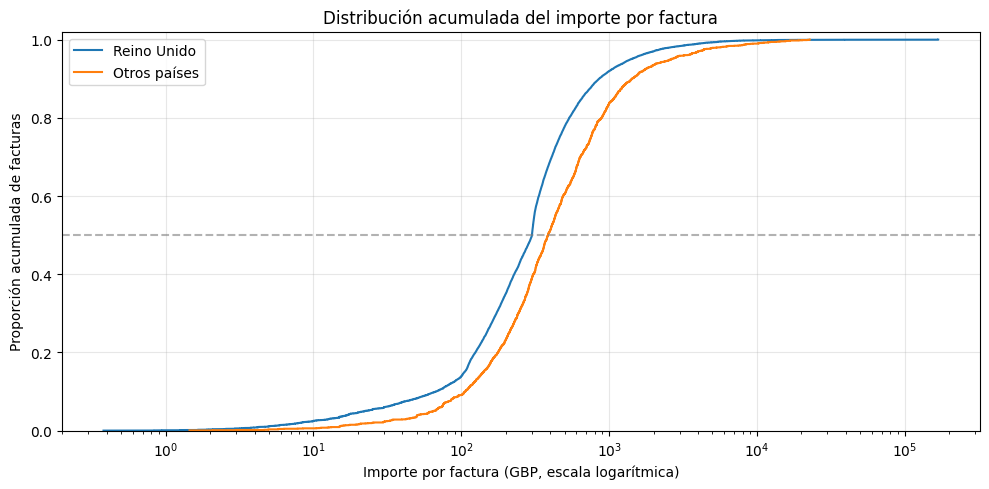

In [7]:
facturas["Grupo"] = np.where(facturas["Pais"] == "United Kingdom", "Reino Unido", "Otros países")

comparacion_grupos = facturas.groupby("Grupo").agg(
    Facturas=("Importe", "size"),
    Media=("Importe", "mean"),
    Mediana=("Importe", "median"),
    Percentil_25=("Importe", lambda x: x.quantile(0.25)),
    Percentil_75=("Importe", lambda x: x.quantile(0.75))
)

display(comparacion_grupos.round(2))

reino_unido = facturas.loc[facturas["Grupo"] == "Reino Unido", "Importe"]
otros_paises = facturas.loc[facturas["Grupo"] == "Otros países", "Importe"]

# Mostramos la proporción de facturas que no supera cada importe.
fig, ax = plt.subplots(figsize=(10, 5))

for nombre, grupo in [("Reino Unido", reino_unido), ("Otros países", otros_paises)]:
    valores = np.sort(grupo.to_numpy())
    proporcion = np.arange(1, len(valores) + 1) / len(valores)
    ax.step(valores, proporcion, where="post", label=nombre)

ax.set_xscale("log")
ax.set_title("Distribución acumulada del importe por factura")
ax.set_xlabel("Importe por factura (GBP, escala logarítmica)")
ax.set_ylabel("Proporción acumulada de facturas")
ax.set_ylim(0, 1.02)
ax.axhline(0.5, color="gray", linestyle="--", alpha=0.6)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
fig.savefig("figures/comparacion_geografica.png", dpi=160, bbox_inches="tight")
plt.show()

### Interpretación de la comparación geográfica

El análisis incluye 17.901 facturas de Reino Unido y 1.872 de otros países.

La mediana es de £300,32 en Reino Unido y de £385,73 en otros países, una diferencia de £85,41. Las medias son de £488,66 y £814,03, respectivamente.

El 50 % central de los importes se encuentra entre £148,49 y £462,28 en Reino Unido, y entre £210,90 y £752,28 en otros países.

Los otros países presentan importes centrales mayores y un rango intercuartílico más amplio. En ambos grupos, la media supera a la mediana, lo que refleja la influencia de las facturas de mayor importe.

Estas diferencias describen las facturas observadas. No demuestran un efecto causal del país ni implican que todos los mercados incluidos en otros países tengan un comportamiento similar.

La distribución acumulada muestra la proporción de facturas que no supera cada importe. En la zona central, la curva de Reino Unido está a la izquierda de la de otros países, aunque Reino Unido presenta el máximo más elevado.

## 8. Preparación del análisis de incertidumbre

Las estadísticas anteriores describen exactamente las facturas seleccionadas del período observado. No necesitamos intervalos de confianza para conocer esos valores históricos.

Como ejercicio de inferencia, utilizaremos bootstrap para explorar la variabilidad de la diferencia entre los importes medios de ambos grupos bajo un modelo de remuestreo de clientes.

Primero seleccionamos las facturas con cliente identificado y contamos cuántas facturas corresponden a cada persona. Esta selección cambia la población analizada, por lo que recalcularemos sus estadísticas.

En el remuestreo mantendremos juntas las facturas de un mismo cliente. También comprobaremos si algún cliente aparece en ambos grupos geográficos antes de definir el procedimiento.

In [8]:
facturas_identificadas = facturas.dropna(subset=["Cliente"]).copy()

resumen_identificados = facturas_identificadas.groupby("Grupo").agg(
    Facturas=("InvoiceNo", "size"),
    Clientes=("Cliente", "nunique"),
    Media=("Importe", "mean"),
    Mediana=("Importe", "median")
)

display(resumen_identificados.round(2))

facturas_por_cliente = facturas_identificadas.groupby("Cliente").size()
grupos_por_cliente = facturas_identificadas.groupby("Cliente")["Grupo"].nunique()

print("Facturas sin cliente excluidas de esta etapa:", len(facturas) - len(facturas_identificadas))
print("Clientes con más de una factura:", (facturas_por_cliente > 1).sum())
print("Máximo de facturas de un cliente:", facturas_por_cliente.max())
print("Clientes presentes en ambos grupos:", (grupos_por_cliente > 1).sum())

,Facturas,Clientes,Media,Mediana
Grupo,,,,
Otros países,1823,418,820.19,385.06
Reino Unido,16579,3916,438.26,299.82


Facturas sin cliente excluidas de esta etapa: 1371
Clientes con más de una factura: 2829
Máximo de facturas de un cliente: 206
Clientes presentes en ambos grupos: 0


### Resultado de la revisión de clientes

La selección con cliente identificado contiene 16.579 facturas de 3.916 clientes de Reino Unido y 1.823 facturas de 418 clientes de otros países.

Excluimos 1.371 facturas sin cliente identificado únicamente de esta etapa. Las medias de la selección son de £438,26 para Reino Unido y £820,19 para otros países.

Hay 2.829 clientes con más de una factura y uno alcanza 206 facturas. Ningún cliente aparece en ambos grupos geográficos.

Estas características justifican mantener juntas las facturas de cada cliente durante el remuestreo.

## 9. Bootstrap por cliente para comparar las medias

Estimamos la variabilidad de la diferencia entre los importes medios por factura:

Diferencia = media de otros países − media de Reino Unido.

En cada repetición seleccionamos clientes con reemplazo dentro de cada grupo, conservando el número original de clientes del grupo. Un cliente puede aparecer varias veces o no aparecer.

Cada cliente seleccionado aporta todas sus facturas. Calculamos la media por factura dividiendo el importe acumulado entre el número de facturas de los clientes seleccionados. No calculamos un promedio simple de las medias de cada cliente.

Realizamos 5.000 repeticiones y utilizamos los percentiles 2,5 y 97,5 de las diferencias para construir un intervalo bootstrap del 95 %.

Este procedimiento supone independencia entre clientes y trata sus historiales observados como representativos del proceso estudiado. No incorpora cambios futuros del negocio ni corrige la selección de clientes con identificación disponible.

Media de Reino Unido: £438.26
Media de otros países: £820.19
Diferencia observada: £381.93
Intervalo bootstrap del 95%: [£134.66, £690.81]


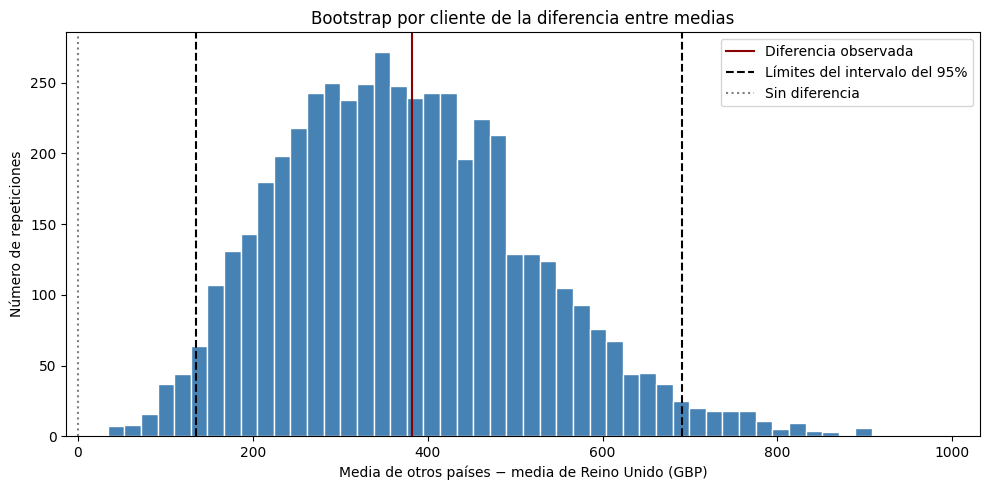

In [9]:
# Resumimos cada cliente sin perder el peso de sus facturas.
resumen_clientes = facturas_identificadas.groupby(["Grupo", "Cliente"]).agg(
    Importe_total=("Importe", "sum"),
    Numero_facturas=("InvoiceNo", "size")
).reset_index()

clientes_uk = resumen_clientes[resumen_clientes["Grupo"] == "Reino Unido"]
clientes_otros = resumen_clientes[resumen_clientes["Grupo"] == "Otros países"]

importes_uk = clientes_uk["Importe_total"].to_numpy()
cantidades_uk = clientes_uk["Numero_facturas"].to_numpy()

importes_otros = clientes_otros["Importe_total"].to_numpy()
cantidades_otros = clientes_otros["Numero_facturas"].to_numpy()

media_uk = importes_uk.sum() / cantidades_uk.sum()
media_otros = importes_otros.sum() / cantidades_otros.sum()
diferencia_observada = media_otros - media_uk

# Fijamos la semilla para reproducir el remuestreo.
generador = np.random.default_rng(42)
repeticiones = 5000
diferencias_bootstrap = np.empty(repeticiones)

for i in range(repeticiones):
    indices_uk = generador.integers(0, len(clientes_uk), size=len(clientes_uk))
    indices_otros = generador.integers(0, len(clientes_otros), size=len(clientes_otros))

    media_uk_remuestreo = importes_uk[indices_uk].sum() / cantidades_uk[indices_uk].sum()
    media_otros_remuestreo = importes_otros[indices_otros].sum() / cantidades_otros[indices_otros].sum()

    diferencias_bootstrap[i] = media_otros_remuestreo - media_uk_remuestreo

limite_inferior, limite_superior = np.percentile(diferencias_bootstrap, [2.5, 97.5])

print(f"Media de Reino Unido: £{media_uk:.2f}")
print(f"Media de otros países: £{media_otros:.2f}")
print(f"Diferencia observada: £{diferencia_observada:.2f}")
print(f"Intervalo bootstrap del 95%: [£{limite_inferior:.2f}, £{limite_superior:.2f}]")

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(diferencias_bootstrap, bins=50, color="steelblue", edgecolor="white")
ax.axvline(diferencia_observada, color="darkred", label="Diferencia observada")
ax.axvline(limite_inferior, color="black", linestyle="--", label="Límites del intervalo del 95%")
ax.axvline(limite_superior, color="black", linestyle="--")
ax.axvline(0, color="gray", linestyle=":", label="Sin diferencia")

ax.set_title("Bootstrap por cliente de la diferencia entre medias")
ax.set_xlabel("Media de otros países − media de Reino Unido (GBP)")
ax.set_ylabel("Número de repeticiones")
ax.legend()

plt.tight_layout()
fig.savefig("figures/bootstrap_clientes.png", dpi=160, bbox_inches="tight")
plt.show()

### Interpretación del bootstrap

Entre las facturas con cliente identificado, el importe medio es de £438,26 en Reino Unido y de £820,19 en otros países. La diferencia observada es de £381,93 por factura.

El intervalo percentil bootstrap del 95 % para la diferencia va de £134,66 a £690,81. Como no incluye cero, el resultado respalda una diferencia positiva bajo los supuestos del procedimiento.

El intervalo es amplio, por lo que existe incertidumbre considerable sobre la magnitud de la diferencia. El remuestreo mantiene juntas las compras de cada cliente y conserva así la dependencia entre sus facturas.

Este resultado corresponde a clientes identificados y a los importes anteriores a cancelaciones posteriores. No demuestra que el país cause las diferencias ni constituye una predicción de compras futuras.

## 10. Conclusiones y limitaciones

### Conclusiones

Analizamos 19.773 facturas con líneas de productos de cantidades y precios positivos.

- La media del importe por factura es de £519,47 y la mediana de £302,59. La diferencia muestra la influencia de las compras grandes sobre el promedio.
- Las 198 facturas por encima del percentil 99 concentran el 19,20 % del importe total.
- Al excluir esas facturas en un escenario de sensibilidad, la media disminuye un 18,38 %, mientras que la mediana permanece relativamente estable.
- La mediana es de £300,32 en Reino Unido y de £385,73 en otros países.
- Entre clientes identificados, la diferencia de medias es de £381,93. El intervalo bootstrap por cliente del 95 % es [£134,66, £690,81].

Para describir una compra habitual, la mediana ofrece una referencia menos sensible a los extremos. La media complementa esa información al reflejar también el peso de las facturas grandes.

### Limitaciones

Los importes excluyen conceptos como envíos, descuentos y comisiones, y no descuentan cancelaciones posteriores. Por tanto, no representan el gasto final del cliente ni las ganancias del negocio.

Las filas exactamente repetidas se conservan porque no contamos con un identificador único de línea para confirmar errores.

El bootstrap excluye las 1.371 facturas sin cliente identificado. Sus resultados no se trasladan automáticamente a esas compras.

El grupo de otros países reúne mercados diferentes. La comparación no controla el tipo de cliente, la composición del pedido ni otros factores que podrían explicar las diferencias.

El bootstrap supone independencia entre clientes y no modela dependencias temporales compartidas, como promociones o estacionalidad. La inferencia depende de estos supuestos.

## 11. Exportación de resultados

Guardamos la tabla por factura, las estadísticas descriptivas, las comparaciones y los resultados del bootstrap.

Las tablas permiten revisar los cálculos y utilizar los resultados en otras herramientas. Los importes se exportan con su precisión de cálculo; el redondeo se utiliza únicamente para presentarlos.

In [10]:
from pathlib import Path

carpeta = Path("resultados")
carpeta.mkdir(exist_ok=True)

facturas.to_csv(carpeta / "facturas.csv", index=False)
estadisticas.to_frame("Importe_GBP").to_csv(carpeta / "estadisticas_importes.csv", index_label="Estadistica")
comparacion_extremos.to_csv(carpeta / "comparacion_extremos.csv", index_label="Indicador")
comparacion_grupos.to_csv(carpeta / "comparacion_geografica.csv")
resumen_identificados.to_csv(carpeta / "clientes_identificados.csv")

resultado_bootstrap = pd.DataFrame({
    "Media_UK": [media_uk],
    "Media_otros": [media_otros],
    "Diferencia": [diferencia_observada],
    "Limite_inferior_95": [limite_inferior],
    "Limite_superior_95": [limite_superior],
    "Repeticiones": [repeticiones],
    "Semilla": [42]
})

resultado_bootstrap.to_csv(carpeta / "resumen_bootstrap.csv", index=False)
pd.DataFrame({"Diferencia_GBP": diferencias_bootstrap}).to_csv(carpeta / "distribucion_bootstrap.csv", index=False)

print("Resultados guardados en:", carpeta.resolve())

Resultados guardados en: /workspace/scratch/10077bf274c4/purchase-statistical-analysis/resultados
